# Uber Fare Prediction - Linear Regression vs Random Forest

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
df = pd.read_csv("uber.csv")
df = df.drop(columns=["Unnamed: 0", "key"])
df = df.dropna()
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.dayofweek
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df.info()

<class 'pandas.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[us, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  int64              
 7   hour               199999 non-null  int32              
 8   day                199999 non-null  int32              
 9   month              199999 non-null  int32              
 10  year               199999 non-null  int32              
dtypes: datetime64[us, UTC](1), float64(5), int32(4), int64(1)
memory usage: 15.3 MB


In [3]:
lat1 = np.radians(df["pickup_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon2 = np.radians(df["dropoff_longitude"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

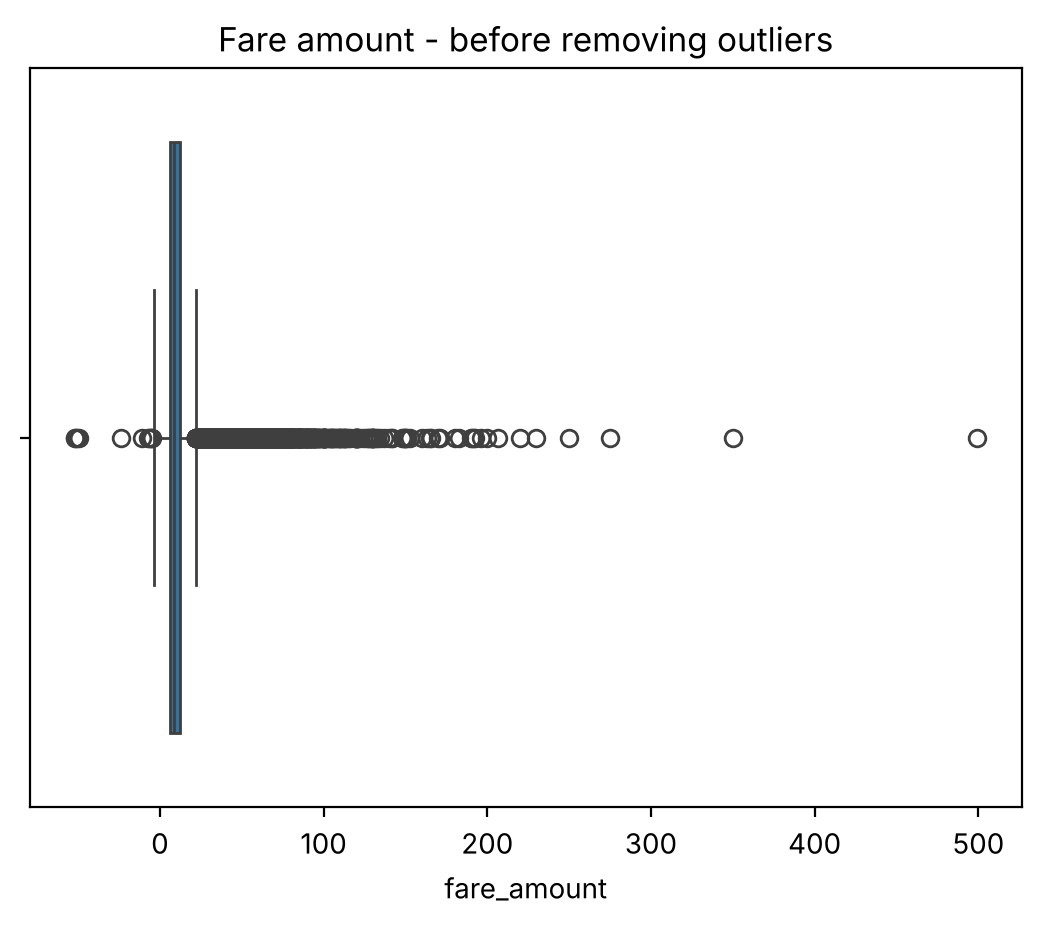

Rows after cleaning: 169023


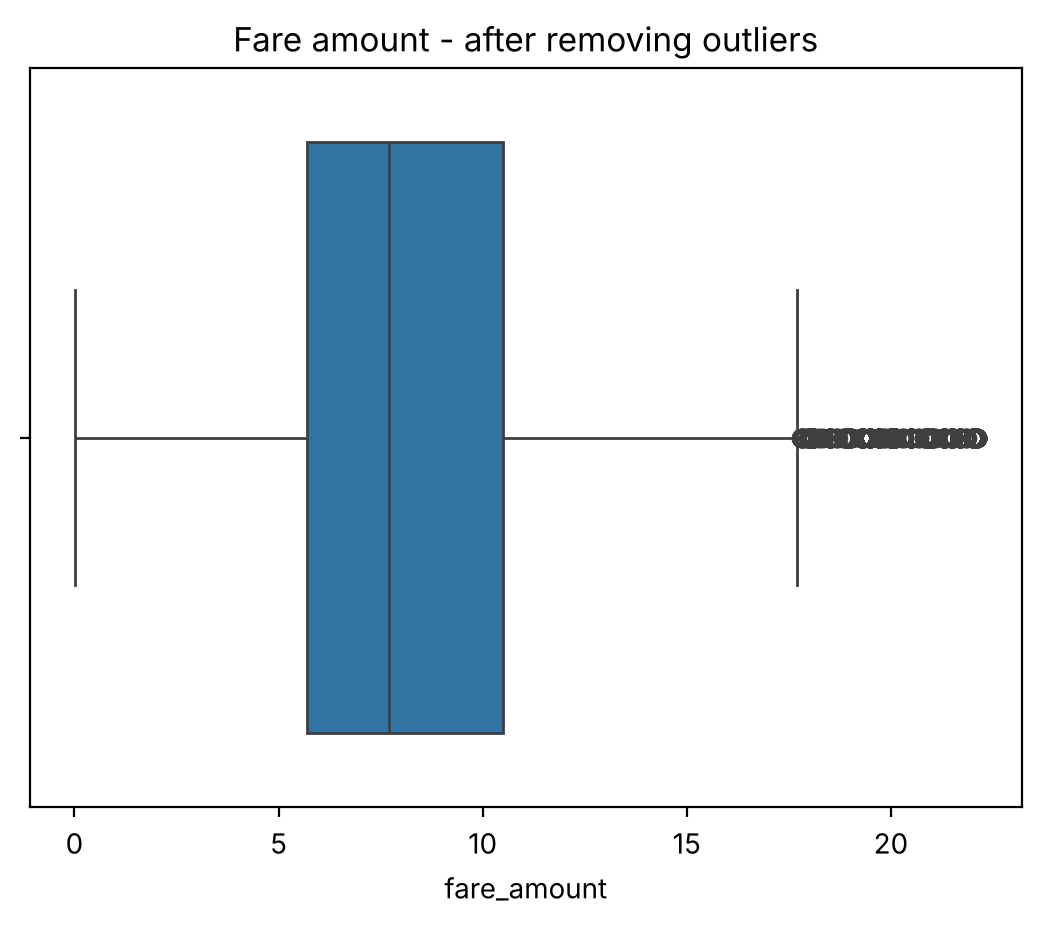

In [4]:
sns.boxplot(x=df["fare_amount"])
plt.title("Fare amount - before removing outliers")
plt.show()

df = df[(df["passenger_count"] >= 1) & (df["passenger_count"] <= 6)]
df = df[(df["fare_amount"] > 0) & (df["distance"] > 0)]
for col in ["fare_amount", "distance"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df[col] >= Q1 - 1.5 * IQR) & (df[col] <= Q3 + 1.5 * IQR)]
print("Rows after cleaning:", len(df))

sns.boxplot(x=df["fare_amount"])
plt.title("Fare amount - after removing outliers")
plt.show()

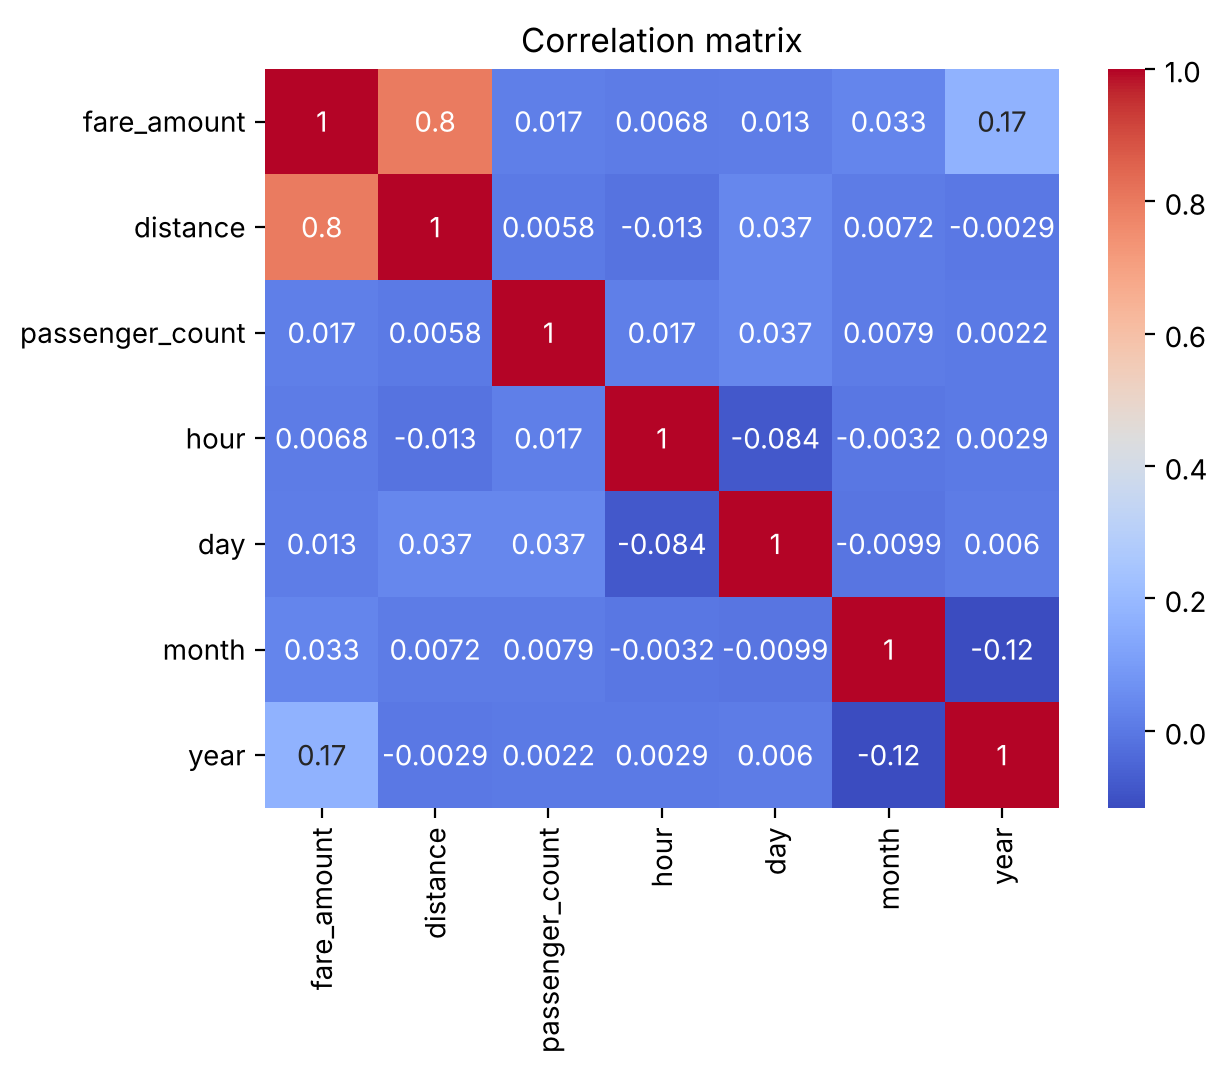

In [5]:
cols = ["fare_amount", "distance", "passenger_count", "hour", "day", "month", "year"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [6]:
X = df[["distance", "passenger_count", "hour", "day", "month", "year"]]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [8]:
for name, pred in [("Linear Regression", lr_pred), ("Random Forest", rf_pred)]:
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name}:  R2 = {r2:.4f}   RMSE = {rmse:.4f}")

Linear Regression:  R2 = 0.6626   RMSE = 2.1604
Random Forest:  R2 = 0.6953   RMSE = 2.0532
